# 주요변수 범용 예측모델 설계 (계절차분 검증판)

3-2의 5개 모델에 **계절(m=4) Auto-ARIMA**를 6번째로 추가해 비교한다.
`seasonal=False`로 고정해온 게 맞는지 6개 변수 전부로 검증(부수 검증은
3-1/3-2에서 이미 끝났으므로 생략).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from scipy import stats
import properscoring as ps

COLS = ["X1_l1", "X2", "X3_l1", "X4", "X5_l1", "X6_l1"]
H = 4
INITIAL_CALIB = 15
N_SAMPLES = 500

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
series = {c: raw[["quarter", c]].dropna().set_index("quarter")[c].values.astype(float) for c in COLS}
var_std = {c: series[c].std() for c in COLS}

def rng_for(name):
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2**32))

print("설정 완료")


설정 완료


## 모델: 3-2의 5개 + 계절 Auto-ARIMA(m=4)

3-2 캐시(5개 모델) + 새로 백테스트한 계절 Auto-ARIMA(`seasonal=True, m=4`)를
합친다.

In [2]:
err_32 = pd.read_pickle("../cache/cache_nb3_2_err_df.pkl")
err_seasonal = pd.read_pickle("../cache/cache_seasonal_err_df.pkl")
err_df = pd.concat([err_32, err_seasonal], ignore_index=True)

FAMILY_LABELS = {
    "naive": "baseline (naive)", "auto_arima": "시계열 (Auto-ARIMA, 비계절)",
    "arima_seasonal": "시계열 (Auto-ARIMA, 계절 m=4)",
    "ols_lag": "회귀 (선형회귀)", "gbm_lag": "트리기반 (GBM)", "gp": "커널/비모수 (GP)",
}
MODELS = list(FAMILY_LABELS.keys())
print("모델:", MODELS)
print("err_df rows:", len(err_df))


모델: ['naive', 'auto_arima', 'arima_seasonal', 'ols_lag', 'gbm_lag', 'gp']
err_df rows: 5352


## CRPS + Likelihood 비교

In [3]:
def crps_score_for(name):
    rng = rng_for(name)
    e = err_df[err_df["model"] == name]
    scores = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            test = g[g["origin"] == origins[i]]
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                row = test[test["h"] == h].iloc[0]
                samples = row["fc_t"] + rng.choice(calib_resid_h, size=N_SAMPLES, replace=True)
                scores.append(ps.crps_ensemble(row["actual_orig"], samples) / var_std[v])
    return np.mean(scores)

def loglik_score_for(name):
    e = err_df[err_df["model"] == name]
    scores = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            sigma_h = calib.groupby("h")["err_t"].std()
            test = g[g["origin"] == origins[i]]
            for h in range(1, H + 1):
                row = test[test["h"] == h].iloc[0]
                scores.append(stats.norm.logpdf(row["err_t"], loc=0, scale=sigma_h[h]))
    return np.mean(scores)

rows = []
for name in MODELS:
    rows.append({"모델": FAMILY_LABELS[name], "CRPS": round(crps_score_for(name), 4),
                 "예측 로그가능도": round(loglik_score_for(name), 3)})
compare_df = pd.DataFrame(rows).set_index("모델").sort_values("CRPS")
display(compare_df)


,CRPS,예측 로그가능도
모델,,
"시계열 (Auto-ARIMA, 비계절)",0.5719,-0.756
커널/비모수 (GP),0.5745,-0.775
회귀 (선형회귀),0.5794,-0.817
"시계열 (Auto-ARIMA, 계절 m=4)",0.6546,-1.112
baseline (naive),0.6590,-0.870
트리기반 (GBM),0.6811,-1.036


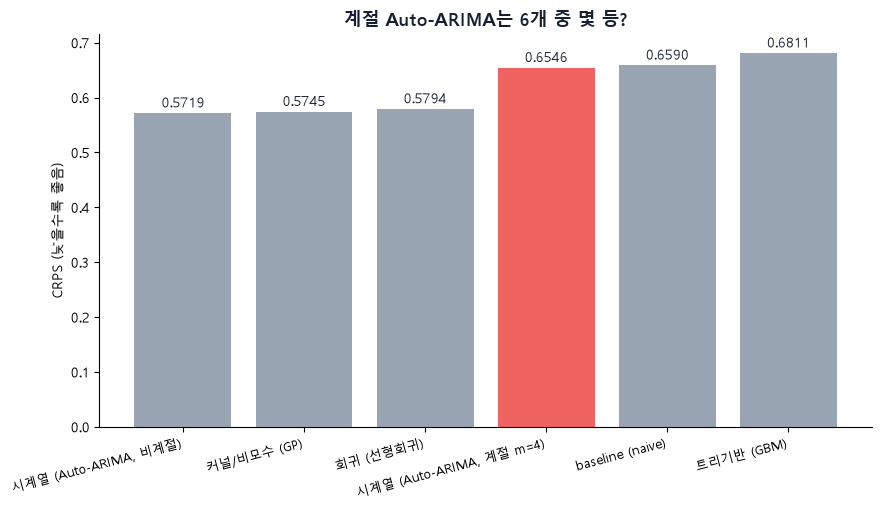

In [4]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

sorted_df = compare_df.sort_values("CRPS")
colors = ["#EF6461" if ("계절" in idx and "비계절" not in idx) else "#9AA5B4" for idx in sorted_df.index]

fig, ax = plt.subplots(figsize=(9, 5.2))
bars = ax.bar(sorted_df.index, sorted_df["CRPS"], color=colors)
for bar, v in zip(bars, sorted_df["CRPS"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.4f}", ha="center", fontsize=10, color="#172033")
ax.set_ylabel("CRPS (낮을수록 좋음)")
ax.set_title("계절 Auto-ARIMA는 6개 중 몇 등?", color="#172033", fontsize=13, fontweight="bold")
plt.setp(ax.get_xticklabels(), rotation=15, ha="right", fontsize=9.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


**해석**: 계절 Auto-ARIMA는 CRPS 0.6546으로 naive(0.6590)보다 조금 나은
정도 — 비계절 Auto-ARIMA(0.5719)·GP·회귀에 크게 못 미친다. Likelihood는
-1.112로 6개 중 최하위.

In [5]:
crps_rank = compare_df["CRPS"].rank()
ll_rank = compare_df["예측 로그가능도"].rank(ascending=False)
combined = pd.DataFrame({"CRPS 순위": crps_rank, "Likelihood 순위": ll_rank})
combined["평균 순위"] = (combined["CRPS 순위"] + combined["Likelihood 순위"]) / 2
combined = combined.sort_values("평균 순위")
display(combined)


,CRPS 순위,Likelihood 순위,평균 순위
모델,,,
"시계열 (Auto-ARIMA, 비계절)",1.0,1.0,1.0
커널/비모수 (GP),2.0,2.0,2.0
회귀 (선형회귀),3.0,3.0,3.0
baseline (naive),5.0,4.0,4.5
"시계열 (Auto-ARIMA, 계절 m=4)",4.0,6.0,5.0
트리기반 (GBM),6.0,5.0,5.5


**해석**: 결합순위도 계절 Auto-ARIMA 5.0으로 꼴찌권(비계절 Auto-ARIMA는
1.0 단독 1위).

## 결론

- 계절 Auto-ARIMA가 CRPS·Likelihood·결합순위 전부에서 비계절보다 뚜렷이
  나쁘다(5.0 vs 1.0).
- AIC(in-sample)는 계절 성분을 선호했지만 out-of-sample은 정반대 — 60분기
  표본으로 계절 파라미터까지 추정하기엔 데이터가 부족해 과적합.
- **`seasonal=False`가 맞다** — 3-2 결론(Auto-ARIMA) 유지.
- **다음 단계**: 4-3에서 세부 13개 모델 경쟁에도 같은 검증.